# Kiểm tra khóa 3 — ôn tập và cách làm

Sau các chương ảnh, chữ và âm thanh, ta có nhiều công cụ, nhưng một buổi làm hai bài mới vẫn có thể rối: bài đầu huấn luyện được model, bài thứ hai chưa có file nộp; hoặc cả hai có điểm trong notebook nhưng ID lại sai khi xuất file. Buổi kiểm tra này luyện mục tiêu **giải hai bài thuộc hai lĩnh vực khác nhau trong sáu giờ**: nối đọc đề, baseline, validation và kiểm output thành một quy trình đi được đến file nộp. Khi thi, thời gian, phần cứng và luật chấm đọc từ đề; lịch và các con số dưới đây là một cách chia để luyện.

> **Mục tiêu sau phần ôn**
>
> - Đọc hai bài, ghi input, output, metric và chọn baseline khả thi cho từng bài.
> - Giải thích hợp đồng tiền xử lý ảnh, chữ, âm thanh trước khi đổi model.
> - Ước điểm theo luật chấm và đọc lỗi theo từng ID để chọn một cải tiến có bằng chứng.
> - Chạy lại suy luận, kiểm ID, schema và ghi kết quả cuối trong ngân sách buổi luyện.

## Một bản đồ để khỏi nhầm nhiệm vụ

Các kiến trúc có thể dùng chung encoder, nhưng head, loss và metric phải theo đề. Image classification cho nhãn hoặc xác suất lớp; object detection cho box, lớp, score; segmentation cho mask. Text classification cho nhãn câu; token classification cho nhãn từng token; ASR cho transcript. Multimodal có thể là phân loại, retrieval hoặc generation, nên tên “multimodal” chưa nói file output phải là gì.

| Câu hỏi cần trả lời | Kiểm trước khi train | Một lỗi nên tìm sớm |
|---|---|---|
| Ảnh thuộc lớp nào? | Kích thước, thứ tự channel, class mapping | Train/test resize khác nhau |
| Vật ở đâu? | Tọa độ box, IoU, ngưỡng, NMS | Đổi chiều rộng với chiều cao hoặc đơn vị box |
| Câu thuộc lớp nào? | Tokenization, length, padding, mask | Caption hoặc người dùng trùng hai tập |
| Âm thanh thuộc lớp nào? | Sample rate, log-mel, processor, group | Crop cùng file vào hai tập |
| Người nói câu gì? | Task transcribe hay translate, normalization WER | Chunk ghép lặp hoặc mất từ |
| Ảnh và chữ có giúp nhau không? | Pair ID, riêng từng nhánh, fusion | Ghép đúng shape nhưng sai cặp |

Với mỗi bài, viết hợp đồng thành hai câu: một hàng nộp gồm gì, và metric chấm nó thế nào. Chưa biết scorer cần xác suất hay nhãn thì đọc phần định dạng trước khi chạy model lớn. Baseline là một đầu ra chấm được, không phải một cell in ra loss.

**Hỏi nhanh.** Đề detection yêu cầu box, class và score cho từng vật. Notebook đang ghi một class cho cả ảnh, với accuracy validation 0.90. Việc đầu tiên cần làm là gì?

- A. Đổi head và file nộp sang dạng box, class, score
- B. Train thêm epoch cho accuracy của ảnh cao hơn
- C. Ghi một box phủ cả ảnh, kèm class đã đoán
- D. Giữ model, chỉ đổi tên cột cho khớp sample

<details><summary>Đáp án</summary>

A. Đổi head và file nộp sang dạng box, class, score

Accuracy 0.90 đo một nhiệm vụ khác. Scorer detection ghép từng box với vật thật theo IoU, nên phải có head ra box, và một file đúng schema. Train thêm chỉ làm tốt hơn câu trả lời cho một câu hỏi sai. Box phủ cả ảnh có IoU rất nhỏ với vật nhỏ, và chỉ có một box khi ảnh có nhiều vật, nên gần như toàn FP và FN. Đổi tên cột cho khớp thì file qua được bước đọc, nhưng nội dung vẫn thiếu box.

</details>

Âm thanh có cùng phân nhánh: một nhãn cho cả clip, một transcript, hay một dãy nhãn theo thời gian khi đề hỏi sự kiện xảy ra lúc nào.

**Hỏi nhanh.** Đề âm thanh: mỗi clip dài 10 giây, cần nộp các khoảng (bắt đầu, kết thúc) có tiếng chó sủa, chấm theo độ trùng thời gian với khoảng thật. Baseline phân loại cả clip “có hay không có chó sủa” đạt accuracy 0.95. Còn thiếu gì?

- A. Không thiếu gì, clip có chó sủa thì nộp khoảng 0–10 giây
- B. Dự đoán theo từng frame, rồi gộp các frame thành khoảng
- C. Đẩy accuracy theo clip lên trên 0.99 rồi mới nộp
- D. Dùng nhiều mel band hơn để thấy rõ tiếng sủa

<details><summary>Đáp án</summary>

B. Dự đoán theo từng frame, rồi gộp các frame thành khoảng

Đề hỏi *lúc nào*, nên đầu ra là một dãy nhãn theo thời gian. Cho điểm từng frame, áp threshold, rồi gộp các frame dương liền nhau thành khoảng. Nộp cả 0–10 giây cho một tiếng sủa dài 1 giây thì độ trùng rất thấp, dù clip được phân loại đúng. Accuracy theo clip cao đến đâu cũng không cho ra vị trí. Số mel band là chi tiết biểu diễn, không đổi được dạng đầu ra.

</details>

## Sáu giờ mẫu: cả hai bài đều cần một đường về đích

Một lịch mẫu có 20 phút đọc hai đề, 60 phút dựng baseline A, 60 phút dựng baseline B, rồi mỗi bài 80 phút cải tiến. 40 phút tiếp theo khóa model và chạy suy luận, 20 phút cuối kiểm file. Tổng là $20+60+60+80+80+40+20=360$ phút. Đề cho ngân sách khác thì giữ thứ tự ưu tiên: hai baseline trước, phần chốt cuối giữ nguyên, phần cải tiến co giãn.



Nếu pipeline A hỏng, đừng dùng cả buổi đổi model để né việc nhìn lỗi. Thu nhỏ về vài sample: input có đúng shape không, label có đúng lớp không, scorer có đọc được output không? Baseline A chạy rồi thì chuyển sang B trước một lượt huấn luyện lớn. Hai baseline tạo hai mốc chấm và cho biết bài nào cần thời gian hơn.

**Hỏi nhanh.** Theo lịch mẫu, baseline A xong ở phút 80. Thực tế A xong ở phút 140, và đội vẫn giữ 60 phút cuối cho suy luận và kiểm file. Còn bao nhiêu phút cho baseline B và cải tiến, và nên làm gì trước?

- A. 220 phút, nên cải tiến A trước khi đụng tới B
- B. 220 phút, nên dựng baseline B trước
- C. 160 phút, nên cải tiến A trước vì A đã chạy
- D. 160 phút, nên dựng baseline B trước

<details><summary>Đáp án</summary>

D. 160 phút, nên dựng baseline B trước

$360 - 140 - 60 = 160$ phút. 220 là quên phần chốt cuối, đúng khoản hay bị cắt nhất. Dựng B trước, mất khoảng 60 phút, để có đường về đích thứ hai, còn lại khoảng 100 phút cho cải tiến. Cải tiến A trước nghe có vẻ hợp lý vì A đã chạy, nhưng nếu lượt cải tiến cũng trễ như baseline thì B không còn thời gian.

</details>

Thứ tự này có lý do trong cách chấm. Nhiều đề quy điểm về thang chung giữa baseline của đề và bài tốt nhất; vòng 2 [USA-NA-AIO 2026](https://www.usaaio.org/attachments/past-problems/2026/usaaio-2026-round-2-day-1-problems.pdf#page=9) dùng $S=\max\left(0,\ \dfrac{X-X_{\mathrm{base}}}{X_{\mathrm{best}}-X_{\mathrm{base}}}\right)$, trong đó $X$ là metric của bài nộp: kém hơn baseline thì được 0. Công thức dùng được cả cho metric càng thấp càng tốt như WER, vì khi đó tử và mẫu cùng đổi dấu. Ví dụ dưới giả sử bài A chấm macro-F1 (baseline 0.50, tốt nhất 0.90), bài B chấm WER (baseline 0.40, tốt nhất 0.15).

In [ ]:
def normalized_score(x, baseline, best):
    return 100 * max(0.0, (x - baseline) / (best - baseline))

print(f"A, macro-F1 0.70 -> {normalized_score(0.70, 0.50, 0.90):.1f}")
print(f"A, macro-F1 0.74 -> {normalized_score(0.74, 0.50, 0.90):.1f}")
print(f"B, WER 0.30      -> {normalized_score(0.30, 0.40, 0.15):.1f}")
print(f"B, WER 0.45      -> {normalized_score(0.45, 0.40, 0.15):.1f}")

A, macro-F1 0.70 -> 50.0
A, macro-F1 0.74 -> 60.0
B, WER 0.30      -> 40.0
B, WER 0.45      -> 0.0


Giả sử đến phút 200, A đạt 0.70 còn B chưa có file. Tám mươi phút cải tiến A lên 0.74 thêm 10 điểm; cùng thời gian, một baseline B đạt WER 0.30 thêm 40 điểm. Một file B kém baseline của đề (WER 0.45) vẫn được 0, nên đường về đích phải vượt baseline đề cho, không chỉ hợp lệ. $X_{\mathrm{best}}$ chưa biết lúc thi; một ước lượng thô đủ để so hai lựa chọn.



**Hỏi nhanh.** Vẫn luật chấm như trong ví dụ, với bài B có baseline WER 0.40 và bài tốt nhất 0.15. Baseline B nhanh nhất ước đạt WER 0.38. Bài B được bao nhiêu điểm?

- A. 8
- B. 92
- C. 38
- D. 0

<details><summary>Đáp án</summary>

A. 8

$(0.38 - 0.40)/(0.15 - 0.40) = 0.02/0.25 = 0.08$, tức 8 điểm. 92 là lấy phần còn thiếu để đến bài tốt nhất. 38 là lấy chính WER. 0 là áp quy tắc “thấp hơn baseline thì được 0” của metric càng cao càng tốt, trong khi với WER, thấp hơn mới là tốt hơn. Baseline sát ngưỡng đề cho đem về ít điểm. Ở đây cải tiến A từ 0.70 lên 0.74, thêm 10 điểm, còn lợi hơn, trừ khi baseline B làm được tốt hơn hẳn 0.38.

</details>

Sau khi có baseline, viết một giả thuyết: “clip dài bị mất từ ở ranh giới”, “ảnh nhỏ có đối tượng bị resize mất”, hoặc “mean pooling bỏ thứ tự”. Chọn một thay đổi kiểm được. Giữ split, metric và tập sample khi so trước và sau; thay đồng thời model, split và normalization thì không biết cải tiến đến từ đâu.

## Ví dụ kiểm output: ID đúng trước điểm tốt

Bài ảnh có ba sample; suy luận theo batch trả về dictionary từ ID sang class, với thứ tự khác manifest. Dự đoán và nhãn reference dưới đây được đặt tay để kiểm riêng khâu xuất file: khâu này phải đúng với bất kỳ model nào.

In [ ]:
import numpy as np

expected_ids = ["img-a", "img-b", "img-c"]
prediction_by_id = {"img-c": 1, "img-a": 2, "img-b": 0}
assert len(expected_ids) == len(set(expected_ids))
assert set(prediction_by_id) == set(expected_ids)
ordered_predictions = np.array([prediction_by_id[sample_id] for sample_id in expected_ids])
assert ordered_predictions.shape == (3,)
assert np.isin(ordered_predictions, [0, 1, 2]).all()
reference_labels = np.array([2, 1, 1])
print(ordered_predictions)
print(f"accuracy minh hoa = {np.mean(ordered_predictions == reference_labels):.3f}")

[2 0 1]
accuracy minh hoa = 0.667


Ta đọc `[2 0 1]` theo `img-a, img-b, img-c`: đúng hai trong ba nhãn. Nếu xuất dictionary theo insertion order, các hàng đi theo `img-c, img-a, img-b` và điểm sai dù prediction theo ID vẫn đúng. Với xác suất, kiểm thêm shape `(N, C)`, số hữu hạn, thứ tự cột lớp và tổng mỗi hàng nếu đề yêu cầu; với mask hay box, kiểm theo schema riêng.



Âm thanh thêm một bẫy: clip dài thường được cắt thành nhiều đoạn để suy luận, nên một ID sinh ra nhiều hàng.

**Hỏi nhanh.** Mỗi file test dài 30 giây được cắt thành ba đoạn 10 giây cho khớp độ dài lúc train. Vì vậy bảng dự đoán có ba hàng cho mỗi ID, mỗi hàng là xác suất của ba lớp. Sample submission có một hàng mỗi ID. Ghi file nộp thế nào?

- A. Giữ cả ba hàng, vì scorer tự lấy trung bình theo ID
- B. Gọi `drop_duplicates("id")`, giữ nhãn của đoạn đầu
- C. Gộp xác suất theo ID, lấy argmax, rồi ghép theo sample
- D. Bỏ phép cắt, đưa nguyên clip 30 giây vào model

<details><summary>Đáp án</summary>

C. Gộp xác suất theo ID, lấy argmax, rồi ghép theo sample

File ba hàng mỗi ID là sai schema, và scorer không hứa gộp giúp. `drop_duplicates` chỉ giữ 10 giây đầu, bỏ đi hai phần ba bằng chứng. Đưa clip 30 giây vào một model học trên 10 giây là đổi hợp đồng input. Code có thể chạy mà không báo lỗi, nhưng phân phối đã khác lúc train. Hãy gộp xác suất các đoạn theo ID, bằng trung bình, hoặc bằng max khi nhãn là “có xuất hiện ở đâu đó”, lấy argmax, rồi ghép theo sample và assert mỗi ID có đúng một hàng.

</details>



## Ví dụ kiểm metric: WER không phải accuracy câu

Ở bài ASR, đối chiếu scorer trên vài chuỗi ngắn trước khi chạy nhiều clip. Hai reference có tổng sáu token theo quy ước tách khoảng trắng; transcript đầu thiếu một token. Hàm `token_errors` là edit distance theo token, đúng quy hoạch động của bài 7.3.

In [ ]:
def token_errors(reference, prediction):
    left, right = reference.lower().split(), prediction.lower().split()
    previous = list(range(len(right) + 1))
    for row, token in enumerate(left, start=1):
        current = [row]
        for column, predicted_token in enumerate(right, start=1):
            current.append(min(
                previous[column] + 1,
                current[column - 1] + 1,
                previous[column - 1] + (token != predicted_token),
            ))
        previous = current
    return previous[-1], len(left)

references = ["em học ai", "mai thi toán"]
transcripts = ["em học", "mai thi toán"]
counts = [token_errors(r, p) for r, p in zip(references, transcripts)]
total_errors = sum(error_count for error_count, _ in counts)
total_tokens = sum(length for _, length in counts)
print(counts)
print(f"corpus WER = {total_errors / total_tokens:.3f}")
print(f"cau dung hoan toan = {sum(r == p for r, p in zip(references, transcripts))}/2")

[(1, 3), (0, 3)]
corpus WER = 0.167
cau dung hoan toan = 1/2


WER bằng $1/6\approx0.167$, còn tỉ lệ câu đúng hoàn toàn là 1/2. WER đếm token sai trên toàn tập; tỉ lệ câu đúng coi câu thiếu một token và câu sai hết như nhau. Hai metric có thể xếp hạng hai model ngược nhau, nên chọn model bằng đúng metric của đề. Chuẩn hóa văn bản trước khi tách token (chữ hoa, dấu câu, số) cũng là một phần của scorer: scorer local phải làm đúng như đề, không hơn, không kém.

**Hỏi nhanh.** Scorer local là hàm `token_errors` ở trên. Scorer của đề thì hạ chữ thường và bỏ dấu câu trước khi tách token. Reference là `em học ai`, transcript là `Em học AI.`. WER theo scorer local và theo scorer của đề lần lượt là bao nhiêu?

- A. 2/3 và 0
- B. 1/3 và 0
- C. 1/3 và 1/3
- D. 0 và 0

<details><summary>Đáp án</summary>

B. 1/3 và 0

`token_errors` đã gọi `.lower()`, nên `Em` khớp với `em`, nhưng vẫn giữ dấu câu. `AI.` thành `ai.`, khác với `ai`, nên local đếm 1 phép thay trên 3 token. Scorer của đề bỏ cả dấu chấm, nên hai chuỗi trùng nhau, và WER bằng 0. 2/3 là bỏ qua `.lower()` trong code. Scorer local lệch như vậy sẽ phạt những model đặt dấu câu đúng, nên có thể chọn nhầm model. Hãy viết lại scorer local theo đúng quy tắc của đề, rồi kiểm trên vài cặp đặt tay như cặp này.

</details>



## Đọc lỗi để chọn cải tiến

Với ảnh, xem một nhóm mẫu sai cùng loại: vật nhỏ, nền lạ, ảnh xoay hay box lệch. Với chữ, xem câu dài, token bị cắt, nhãn ít mẫu hoặc domain mới. Với âm, xem sample rate, clip im lặng, tiếng nền và độ dài. Với multimodal, đo từng nhánh riêng, kiểm cặp và thử thiếu nguồn. “Model không tốt” là một kết luận quá rộng để quyết định bước tiếp.

Một kết quả nên ghi ít nhất: tên thử nghiệm, hash hoặc cấu hình input, split, checkpoint và seed, metric, thời gian suy luận và nhận xét lỗi. Điểm tăng rất nhỏ trên validation ít mẫu cần được đọc theo từng mẫu, hoặc kiểm trên fold khác khi ngân sách cho phép. Không chọn model vì một seed tình cờ tốt rồi bỏ qua chi phí chạy.

Đọc theo ID cũng là cách đọc một bảng ablation. Dưới đây là dự đoán của ba cấu hình trên 25 mẫu validation của một bài ảnh + chữ ba lớp: chỉ ảnh, chỉ chữ, và fusion.

In [ ]:
import numpy as np

labels      = np.array([0, 1, 2, 1, 0, 2, 2, 0, 1, 1, 0, 2, 1, 0, 2, 1, 0, 2, 0, 1, 2, 0, 1, 2, 0])
image_pred  = np.array([0, 1, 2, 2, 0, 1, 2, 0, 1, 1, 0, 0, 1, 0, 0, 1, 0, 1, 0, 1, 2, 0, 1, 2, 0])
text_pred   = np.array([1, 1, 2, 1, 0, 1, 2, 0, 0, 1, 0, 2, 2, 0, 1, 1, 0, 2, 0, 1, 2, 1, 1, 2, 0])
fusion_pred = np.array([0, 1, 2, 1, 0, 1, 2, 0, 0, 1, 0, 2, 1, 0, 0, 1, 0, 2, 0, 1, 2, 1, 1, 2, 0])

image_ok, text_ok, fusion_ok = (pred == labels for pred in (image_pred, text_pred, fusion_pred))
for name, ok in [("anh", image_ok), ("chu", text_ok), ("fusion", fusion_ok)]:
    print(f"{name:6s} accuracy = {ok.mean():.2f}")
for name, mask in [("fusion sua", ~image_ok & fusion_ok),
                   ("fusion lam sai", image_ok & ~fusion_ok),
                   ("ca ba cung sai", ~image_ok & ~text_ok & ~fusion_ok)]:
    print(f"{name:14s}: {np.flatnonzero(mask).tolist()}")

anh    accuracy = 0.80
chu    accuracy = 0.76
fusion accuracy = 0.84
fusion sua    : [3, 11, 17]
fusion lam sai: [8, 21]
ca ba cung sai: [5, 14]


Fusion hơn ảnh 0.04, tức đúng một mẫu, nhưng năm ID đổi kết quả: sửa ba (3, 11, 17), làm sai thêm hai (8, 21). Ở ID 8 và 21 nhánh chữ sai và kéo fusion theo; đọc hai mẫu ấy cho biết nên giảm trọng số chữ hay sửa dữ liệu chữ. Hai ID 5 và 14 cả ba cấu hình cùng sai: thêm modality không cứu được, cần xem lại nhãn hoặc tìm một nguồn thông tin khác. Với 25 mẫu, một mẫu là 0.04; chênh cỡ ấy cần thêm fold hoặc thêm dữ liệu trước khi kết luận.



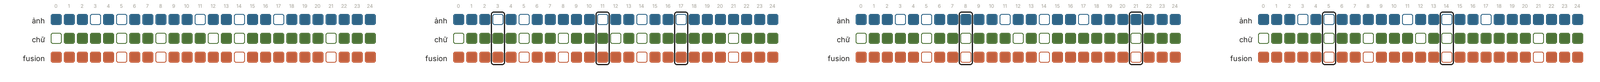

**Hỏi nhanh.** Với 25 dự đoán ở trên, xét mọi cách gộp chỉ chọn giữa dự đoán của nhánh ảnh và của nhánh chữ ở từng mẫu. Cách gộp tốt nhất có thể, tức luôn chọn đúng nhánh đúng, đạt accuracy bao nhiêu?

- A. 0.92
- B. 0.84
- C. 0.96
- D. 1.00

<details><summary>Đáp án</summary>

A. 0.92

Chỉ có hai ID là 5 và 14 mà cả hai nhánh cùng sai. Mọi ID khác có ít nhất một nhánh đúng, nên trần là $23/25 = 0.92$. Fusion hiện ở 0.84, nên còn 0.08 nằm ở việc chọn nhánh, cụ thể là ID 8 và ID 21. 0.96 là chỉ trừ một ID. 1.00 là tưởng gộp hai nguồn luôn sửa được mọi lỗi. Muốn vượt 0.92 thì phải có thông tin mới, chứ không chỉ đổi cách gộp.

</details>

Phần đọc lỗi cũng kiểm leakage. Nếu điểm quá cao, tìm sample trùng, cùng người nói, bản sao ảnh, caption chứa nhãn hoặc đoạn audio cắt từ một file chung. Điểm cao nhờ đường tắt có thể sụp khi dữ liệu test khác. Mục tiêu của buổi ôn là làm được pipeline mới, không học thuộc một bộ test.

## Chốt model và kiểm ở tiến trình mới

Trong notebook, biến cũ có thể còn tồn tại dù cell nạp checkpoint chưa chạy; file nộp có thể dùng prediction của một model trước. Chạy lại từ input bằng cấu hình đã khóa: tiền xử lý → checkpoint → suy luận → xuất file → scorer hoặc bước kiểm định dạng. Kiểm ID đủ một lần, không thiếu, không trùng, không NaN, đúng cột, nhãn và schema. Một ví dụ nhỏ chạy qua toàn chuỗi trước batch lớn bắt được phần lớn lỗi ghép nối.

Checkpoint pretrained chỉ là model đã học khi weights thật được nạp cùng processor hoặc template của nó; `Model(config)` có đúng kiến trúc nhưng trọng số ngẫu nhiên. Khi asset không có trong môi trường được phép, dùng một baseline chạy được trên máy chấm; số liệu trên model card không phải điểm của pipeline. Audio có sample rate khác phải resample có lọc; mask của ảnh, chữ và âm thanh sau encoder phải theo độ dài mới. Với model sinh (VLM, LLM, ASR encoder–decoder), cấu hình sinh cũng thuộc phần phải khóa.

**Hỏi nhanh.** Chạy lại suy luận VLM ở một tiến trình mới, cùng checkpoint, prompt và ảnh, thì 14 trong 200 câu trả lời khác với lần chạy trong notebook. Cấu hình sinh đang là `do_sample=True, temperature=0.7`. Chốt file nộp thế nào?

- A. Chạy thêm vài lần, nộp lần có validation cao nhất
- B. Giữ sampling, vì file nào cũng hợp lệ, rồi nộp lần cuối
- C. Sinh bằng greedy, chạy lại hai lần và so khớp từng ID
- D. Giảm `max_new_tokens` để câu trả lời ổn định hơn

<details><summary>Đáp án</summary>

C. Sinh bằng greedy, chạy lại hai lần và so khớp từng ID

Sampling chọn token ngẫu nhiên theo phân phối, nên mỗi lần chạy cho một file khác. Với hỏi đáp có một đáp án đúng, giải mã greedy, tức `do_sample=False`, cho kết quả xác định. Hai lần chạy khớp nhau là bằng chứng pipeline tái lập được. Chọn lần chạy có validation cao nhất là tune trên nhiễu, nên điểm ấy lạc quan. Nộp lần cuối của sampling thì không ai tái tạo được file. `max_new_tokens` chỉ giới hạn độ dài, không bỏ được tính ngẫu nhiên.

</details>

Sau buổi luyện, kiểm xem mỗi bài đã có output chấm được, một baseline có validation, ít nhất một so sánh giải thích được và một lượt suy luận tái lập. Nếu chưa xong một bài, ghi chính xác khâu dừng: đọc dữ liệu, tiền xử lý, train, scorer hay xuất file. Buổi sau luyện đúng khâu ấy trên một bài nhỏ hơn, thay vì train lại model lớn.

## Khi đi thi

- **Đọc cả hai đề trước khi code.** Với mỗi bài ghi: một hàng nộp gồm gì, metric và chiều tốt, baseline của đề, luật về asset, Internet và GPU.
- **Hai đường về đích trước, cải tiến sau.** Mỗi baseline đi hết đọc dữ liệu → model → file → scorer và vượt baseline đề cho; ước điểm chuẩn hóa để chọn bài đáng đầu tư tiếp.
- **Scorer local khớp scorer của đề.** Cùng chuẩn hóa văn bản, cùng kiểu trung bình (macro hay micro), cùng cách ghép ID; thử trên vài hàng đặt tay trước khi dùng để chọn model.
- **Đọc lỗi theo ID trước khi đổi model.** So từng mẫu giữa hai cấu hình; trên validation nhỏ, một mẫu đã là vài phần trăm.
- **Khóa sớm, chạy lại ở tiến trình mới.** Nạp checkpoint và processor đã lưu, sinh greedy, đo thời gian suy luận toàn test; không khởi động một lượt chạy dài hơn thời gian còn lại.
- **Kiểm file cuối và giữ bản dự phòng.** Đủ ID, không trùng, không NaN, giá trị thuộc tập nhãn; file đã qua kiểm thì giữ lại cho đến khi có file tốt hơn cũng đã qua kiểm.

## Tóm tắt

CNN hay ViT xử lý ảnh nhưng head quyết định nhiệm vụ; tokenizer và encoder xử lý chữ nhưng mask và độ dài quyết định phần được nhìn thấy; audio encoder đọc waveform nhưng sample rate quyết định thời gian; fusion dùng nhiều nguồn nhưng ID và căn thời gian quyết định chúng nói về cùng một sự việc. Tất cả quay về split và metric để biết một thay đổi có giúp trên dữ liệu mới không.

- Hai bài cần hai baseline có đầu ra chấm được và vượt baseline của đề; dành thời gian rõ cho suy luận và kiểm file.
- Input, output và metric quyết định pipeline; scorer local phải chấm đúng như scorer của đề.
- Đọc lỗi theo từng ID và đổi một phần mỗi lượt để có bằng chứng cải tiến.
- Khóa cấu hình, kể cả cách sinh; chạy lại ở tiến trình mới và kiểm ID, schema trước khi nộp.

## Kiểm tra cuối bài

**Câu 1.** Đề phân loại ý định từ câu nói. Đội nối một ASR pretrained, có WER validation 0.25, với một bộ phân loại chữ. Bộ phân loại được train trên transcript do người gõ, có sẵn trong dữ liệu train. Trên transcript người gõ của validation, macro-F1 là 0.88. Cả pipeline chạy từ audio validation chỉ được 0.69. Cải tiến nào nhắm đúng chỗ hở?

- A. Train bộ phân loại thêm epoch trên transcript người gõ
- B. Train bộ phân loại trên transcript do ASR sinh ra
- C. Báo 0.88 là điểm của pipeline, vì ASR là phần pretrained
- D. Bỏ dấu khi tính WER để hai bước khớp nhau hơn

<details><summary>Đáp án</summary>

B. Train bộ phân loại trên transcript do ASR sinh ra

Test luôn đi qua ASR, nên bộ phân loại sẽ gặp từ sai, từ thiếu mà lúc train chưa từng thấy. Khoảng cách từ 0.88 xuống 0.69 là độ lệch giữa đầu vào lúc train và lúc thi. Hãy chạy ASR trên audio train, train bộ phân loại trên transcript ấy, và chọn cấu hình trên một validation cũng đi qua ASR. Train thêm trên transcript người gõ chỉ học kỹ hơn thứ mà test không có. 0.88 là điểm của một nhiệm vụ không có trong đề. Cách tính WER không làm đổi chữ mà bộ phân loại nhận vào.

</details>

**Câu 2.** Một CNN 1D trên log-mel cho mỗi frame của clip một điểm $z_t$, và $z_t$ cao nghĩa là frame ấy có tiếng mưa. Theo nhãn của đề, clip dương nếu mưa chiếm ít nhất nửa thời lượng. Gộp $z_1, \dots, z_T$ thành một điểm của clip, rồi so với ngưỡng, bằng cách nào thì khớp với định nghĩa nhãn?

- A. Lấy max của các $z_t$
- B. Lấy min của các $z_t$
- C. Lấy trung bình của các $z_t$
- D. Lấy trung vị của các $z_t$

<details><summary>Đáp án</summary>

D. Lấy trung vị của các $z_t$

Trung vị vượt ngưỡng khi quá nửa số frame vượt ngưỡng, và không vượt khi quá nửa số frame không vượt. Chỉ khi đúng một nửa, tức $T$ chẵn, kết quả mới phụ thuộc hai giá trị ở giữa. Cách viết khớp nguyên văn định nghĩa nhãn là đếm tỉ lệ frame vượt ngưỡng rồi so với 0.5. Max cao chỉ cần một frame có mưa, tức “có ít nhất một lần”. Min cao thì đòi mọi frame đều có mưa. Trung bình bị kéo bởi độ lớn: ba frame $z = 10$ và bảy frame $z = -1$ cho trung bình 2.3, vượt ngưỡng 0, dù mưa chỉ chiếm 30% clip. Phép gộp phải chọn theo định nghĩa nhãn, không theo thói quen.
Phỏng theo: [MIT 6.036 · Final, Spring 2022 · Q8(b)](https://introml.mit.edu/_static/fall22/final/review/6036_final_sp22.pdf#page=21)

</details>

**Câu 3.** Mỗi mẫu là một video 10 giây. Nhánh ảnh lấy 25 khung hình mỗi giây, được 250 vector. Audio encoder trả 50 vector mỗi giây, được 500 vector. Để fusion theo từng bước, đội lấy 250 vector audio đầu cho khớp shape. Code chạy, hai nhánh cùng shape `(250, d)`, nhưng fusion trên validation chỉ ngang với nhánh ảnh. Nên làm gì trước?

- A. Kết luận audio không giúp gì và bỏ nhánh audio
- B. Đổi chỉ số của mỗi cặp ra giây, rồi assert hai bên trùng mốc
- C. Thêm assert hai nhánh cùng shape trước bước fusion
- D. Train fusion thêm vài epoch để nó tự học cách căn

<details><summary>Đáp án</summary>

B. Đổi chỉ số của mỗi cặp ra giây, rồi assert hai bên trùng mốc

Shape khớp chưa có nghĩa hai nguồn mô tả cùng một thời điểm. Khung $i$ ở giây $i/25$, còn vector audio $i$ ở giây $i/50$. Cặp thứ 200 ghép khung ở giây 8.0 với âm ở giây 4.0, và nửa sau của audio không hề vào model. Một assert theo thời gian trên một mẫu bắt được lỗi này ngay. Sửa bằng cách gộp hai vector $2i$ và $2i + 1$, cùng thuộc khoảng $[i/25, (i + 1)/25)$ giây, cho khung $i$, rồi mới so lại với nhánh ảnh. Bỏ audio là kết luận từ một ablation đo trên dữ liệu ghép sai. Assert shape đã qua, nên không bắt được gì. Train thêm không đưa được nửa sau của audio trở lại, và không cho model biết cặp nào bị lệch.
Phỏng theo: [NOAI 2026 Singapore · Vòng sơ loại · Câu 266](https://aisingapore.org/wp-content/uploads/2026/04/NOAI-2026-Preliminary-Round-Assessment-300-MCQs-Google-Forms.pdf#page=95)

</details>

**Câu 4.** Đề hỏi đáp về ảnh có 1500 bộ (ảnh, câu hỏi, đáp án) để train, một GPU T4, và được dùng hai checkpoint pretrained: một vision encoder, và một language model chỉ đọc chữ, chưa từng được nối với nhau. Nên train phần nào?

- A. Fine-tune toàn bộ language model, giữ vision encoder
- B. Train một VLM nhỏ từ đầu cho vừa bộ nhớ T4
- C. Giữ nguyên hai model, chỉ học lớp nối ảnh vào language model
- D. Không train gì, mô tả ảnh bằng chữ rồi đưa vào prompt

<details><summary>Đáp án</summary>

C. Giữ nguyên hai model, chỉ học lớp nối ảnh vào language model

Đây là cách làm của Flamingo: giữ cố định vision encoder và language model, chỉ học các lớp nối, như projection hoặc cross-attention, để đưa đặc trưng ảnh vào language model. Số tham số cần học ít, nên vừa với 1500 mẫu và vừa với T4, mà hai model không mất những gì đã học. Fine-tune cả language model cần bộ nhớ cho trạng thái optimizer của toàn model, và dễ overfit 1500 mẫu. 1500 mẫu quá ít để train VLM từ đầu. Đề không cho model nào biến ảnh thành chữ, nên không có mô tả để đưa vào prompt. Train xong, hãy thử thay ảnh bằng ảnh của mẫu khác. Accuracy phải giảm, nếu không thì model đang trả lời chỉ từ câu hỏi.
Phỏng theo: [NOAI 2026 Singapore · Vòng sơ loại · Câu 263](https://aisingapore.org/wp-content/uploads/2026/04/NOAI-2026-Preliminary-Round-Assessment-300-MCQs-Google-Forms.pdf#page=94)

</details>

**Câu 5.** Một clip dài 590 giây được cắt thành 21 đoạn 30 giây, hai đoạn kề nhau chồng lên nhau 2 giây. ASR chép đúng vùng chồng ở cả hai đoạn, rồi các transcript được nối thẳng vào nhau. Mỗi vùng chồng có trung bình 5 từ, và reference có 1500 từ. So với ghép đúng, WER tăng thêm khoảng bao nhiêu?

- A. 0.067
- B. 0.133
- C. 0.033
- D. 0, vì WER không tính từ thừa

<details><summary>Đáp án</summary>

A. 0.067

21 đoạn có 20 chỗ nối, mỗi chỗ lặp 5 từ, tổng cộng 100 từ thừa. Mỗi từ thừa là một insertion, nên WER tăng $100/1500 \approx 0.067$. 0.133 là đếm cả hai bản của vùng chồng là lỗi, trong khi một bản khớp với reference. 0.033 là chia đôi số từ lặp. WER bằng $(S + D + I)/N$, nên có tính từ thừa. Hãy ghép theo timestamp: mỗi đoạn chỉ giữ những từ nằm trong nửa vùng chồng phía mình, rồi đo lại WER trên vài clip dài.

</details>

**Câu 6.** Phân loại cảm xúc review sản phẩm bằng một encoder giới hạn 128 token, phần vượt bị cắt từ cuối. Đọc lỗi validation thì thấy 70% câu sai là review dài hơn 128 token, và nhiều review chốt ý ở câu cuối, như “… nhưng dùng một tuần thì hỏng”. Nên thử gì trước?

- A. Train thêm epoch để model hiểu review dài hơn
- B. Bỏ các review dài khỏi tập train cho đỡ nhiễu
- C. Tăng `max_length` lên 1024 với cùng checkpoint
- D. Giữ 64 token đầu và 64 token cuối, rồi đo lại

<details><summary>Đáp án</summary>

D. Giữ 64 token đầu và 64 token cuối, rồi đo lại

Câu chốt ý đã bị cắt trước khi vào model. Train lâu hơn hay bỏ review dài khỏi train đều không đưa nó trở lại, mà bỏ khỏi train còn làm train lệch xa test hơn. Nhiều encoder kiểu BERT chỉ có bảng vị trí cho 512 token, nên 1024 vượt bảng. Ngay trong giới hạn, chi phí attention cũng tăng theo bình phương độ dài. Cắt cả đầu lẫn cuối giữ nguyên ngân sách 128 token, mà vẫn giữ được phần chốt. Hãy đo lại riêng trên nhóm review dài, và trên toàn validation.

</details>

**Câu 7.** Train và validation là giọng nói thu ở 16 kHz, còn đề cho biết test là cuộc gọi điện thoại thu ở 8 kHz. Đội resample test lên 16 kHz cho khớp processor, và validation có macro-F1 0.90. Điểm này đã dự đoán được điểm test chưa, và nên làm gì?

- A. Được rồi, vì resample đã đưa test về đúng hợp đồng
- B. Được, nếu đưa thẳng audio 8 kHz vào processor
- C. Chưa, cần hạ validation xuống 8 kHz rồi nâng lại để đo
- D. Chưa, cần tăng số mel band để bù dải tần bị thiếu

<details><summary>Đáp án</summary>

C. Chưa, cần hạ validation xuống 8 kHz rồi nâng lại để đo

Bản 8 kHz chỉ chứa tần số tới 4 kHz, là Nyquist của nó. Nâng lên 16 kHz không tạo lại được phần trên 4 kHz, nên các mel band cao của test gần như trống, trong khi lúc train luôn có. Hãy hạ validation xuống 8 kHz rồi nâng lại 16 kHz để đo đúng tình huống của test, và train trên dữ liệu đã qua cùng phép biến đổi ấy, hoặc trộn vào làm augmentation. Đưa thẳng 8 kHz vào processor 16 kHz làm sai cả trục thời gian lẫn trục tần số. Thêm mel band không tạo ra được thông tin không có.

</details>

**Câu 8.** Đề phân loại bình luận tiếng Việt. Đội lấy một checkpoint có tokenizer tự hạ chữ thường và bỏ dấu. Bước chuẩn hóa của nó biến `Bán bàn bạn ban` thành `ban ban ban ban`. Nên làm gì?

- A. Đổi sang tokenizer và checkpoint giữ dấu tiếng Việt
- B. Giữ nguyên, vì encoder có ngữ cảnh sẽ tự phân biệt bốn từ
- C. Chuẩn hóa NFC trước khi đưa vào tokenizer là đủ
- D. Tăng `max_length` để bù các token đã bị gộp

<details><summary>Đáp án</summary>

A. Đổi sang tokenizer và checkpoint giữ dấu tiếng Việt

Thông tin đã mất trước khi vào encoder: “bán”, “bàn” và “bạn” thành cùng một token, và ngữ cảnh chỉ đoán lại được một phần. NFC chỉ thống nhất cách mã hóa dấu, còn bước bỏ dấu nằm trong tokenizer, nên dấu vẫn bị xóa. Chỉ tắt bước bỏ dấu cũng không đủ, vì checkpoint đã học trên văn bản không dấu, và chưa từng gặp các token có dấu. `max_length` không liên quan. Trước khi train, hãy tokenize rồi decode vài câu có dấu để kiểm.

</details>

**Câu 9.** Phân loại sản phẩm từ ảnh và mô tả. Trên validation, chỉ chữ được 0.97, chỉ ảnh được 0.71, fusion được 0.97. Đọc dữ liệu thì thấy 80% mô tả trong train chứa đúng tên lớp, như “áo khoác nam …”. Đề nói mô tả ở test do người mua viết tự do. Nên làm gì trước?

- A. Nộp model chỉ dùng chữ, vì nó cao nhất và nhẹ nhất
- B. Che tên lớp trong mô tả validation, rồi đo lại từng nhánh
- C. Bỏ nhánh ảnh, vì fusion không hơn model chỉ dùng chữ
- D. Đặt trọng số ảnh 0.5 trong fusion cho cân hai nhánh

<details><summary>Đáp án</summary>

B. Che tên lớp trong mô tả validation, rồi đo lại từng nhánh

0.97 có thể đến từ một đường tắt: model đọc tên lớp trong mô tả, thứ mà test không có. Hãy che hoặc thay tên lớp trong mô tả validation để đo đúng tình huống của test, rồi train với mô tả đã che để buộc model dùng ảnh và phần mô tả còn lại. Chọn theo con số 0.97 hiện tại, như nộp model chỉ dùng chữ hay bỏ ảnh, là tin vào đường tắt. Trọng số 0.5 chọn tay không dựa trên phép đo nào.

</details>

**Câu 10.** Còn 20 phút. File A và file B, lấy từ checkpoint epoch 6 của B, đã qua kiểm ID và schema, và đã nằm trong thư mục nộp. Checkpoint epoch 9 của B có macro-F1 validation cao hơn 0.03, nhưng suy luận toàn bộ test đo được mất 25 phút. Nên làm gì?

- A. Chạy suy luận epoch 9, và nộp khi đủ hàng
- B. Tăng batch cho kịp, không cần đo lại bộ nhớ
- C. Sửa tay nhãn của vài ID khó trong B cho chắc
- D. Giữ file epoch 6, và ghi lại epoch 9 vào báo cáo

<details><summary>Đáp án</summary>

D. Giữ file epoch 6, và ghi lại epoch 9 vào báo cáo

25 phút lớn hơn 20 phút còn lại, nên lượt chạy không xong, lại còn chiếm mất thời gian kiểm file. Tăng batch mà chưa đo có thể hết bộ nhớ giữa chừng, và chênh 0.03 trên validation chưa đáng để liều mất file. Gán nhãn tay cho dữ liệu test thường bị cấm, và có thể mất điểm cả phần. Hãy giữ bản đã kiểm, và ghi thí nghiệm epoch 9 vào báo cáo. Lần sau, đo thời gian suy luận sớm để không gặp lại tình huống này.

</details>

## Đọc thêm

- scikit-learn — [Model evaluation](https://scikit-learn.org/stable/modules/model_evaluation.html). Đối chiếu metric thay vì dùng `score` mặc định cho mọi nhiệm vụ.
- PyTorch — [Saving and Loading Models](https://docs.pytorch.org/tutorials/beginner/saving_loading_models.html). Luyện lưu, nạp lại checkpoint và đưa model về eval trước suy luận.
- [IOAI 2026 — đề thi cá nhân](https://github.com/IOAI-official/IOAI-2026/tree/main/Individual-Contest). Mỗi task tách phần statement và phần định dạng output; luyện đọc phần định dạng trước khi chạy model.
- Các mục đọc thêm trong 7.1–7.4. Chọn nguồn theo khâu đang cần sửa: sample rate và STFT, group split, CTC và WER, hoặc fusion và template.